# 34 — Causalidade de Granger por UF e tipologia

Análise nas 27 UFs, nos dois períodos, considerando as **16 tipologias da classificação operacional do Atlas**, sem agrupamentos.

Esta etapa avalia **precedência preditiva**, não impacto causal. O teste F conjunto verifica se os lags do desastre agregam informação além dos lags da inadimplência. Seleção de p entre 1 e 6 por BIC; correção Benjamini–Hochberg dentro de UF × período.

## 1. Leitura, transformações e verificações

A dependente é `Δlog(I)` e cada tipologia é `Δlog(1+D)`. Incluímos intercepto e 11 indicadores mensais. Não rejeitar a hipótese nula de KPSS é compatível com estacionariedade, mas não constitui prova.

In [1]:
from pathlib import Path
import os, sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
if 'TCC_BASE_CSV' not in os.environ:
    os.environ['TCC_BASE_CSV']=str(ROOT/'data/processed/df_tcc_2013_2024.csv')
from analise_estadual import load, TIPOS
D=ROOT/'outputs/tables/revisao_estadual_20261019'
A=ROOT/'outputs/tables/auditoria_metodologica_20261020'
S=ROOT/'outputs/tables/sarimax_criterios_independentes_20261020'
df=load()
print(f'Painel: {len(df)} observações, {df.uf.nunique()} UFs, {df.mes_ano.nunique()} meses, {len(TIPOS)} tipologias')

Painel: 3888 observações, 27 UFs, 144 meses, 16 tipologias


## 2. Estimação e suporte

**Para recalcular integralmente**, altere `REESTIMAR = True`. Os resultados abaixo foram executados anteriormente sobre esta mesma base e são revalidados no notebook.

In [2]:
REESTIMAR=False
if REESTIMAR:
    from analise_estadual import granger
    _=granger(df)
g=pd.read_csv(D/'granger_aplicacoes.csv')
assert len(g)==27*2*16
print('Aplicações',len(g),'estimáveis',int(g.status.eq('estimado').sum()),'constantes',int(g.status.eq('exposição transformada constante').sum()),'sem posto',int(g.status.eq('sem modelo de posto completo na grade').sum()))
print('Rejeições nominais',int(g.rejeicao_nominal.sum()),'corrigidas BH',int(g.rejeicao_bh.sum()))

Aplicações 864 estimáveis 627 constantes 227 sem posto 10
Rejeições nominais 45 corrigidas BH 14


## 3. Resultados que sobreviveram ao BH

In [3]:
sig=g[g.rejeicao_bh].copy()
assert len(sig)==14
print(sig[['uf','periodo','tipologia','p_lags','p','q_bh','ljungbox_p']].to_string(index=False))
print('Com rejeição do Ljung–Box:',len(sig[sig.ljungbox_p<.05]))

uf periodo                          tipologia  p_lags            p         q_bh  ljungbox_p
AL     Pré                   tipo_alagamentos     1.0 7.469455e-03 3.983709e-02    0.274391
AL     Pré               tipo_chuvas_intensas     1.0 1.135188e-02 4.540753e-02    0.310762
AL     Pré                    tipo_enxurradas     1.0 7.469455e-03 3.983709e-02    0.274391
AL     Pré                    tipo_inundacoes     1.0 7.469455e-03 3.983709e-02    0.274391
MG     Pré               tipo_chuvas_intensas     3.0 3.700429e-04 5.920687e-03    0.802680
MT     Pré           tipo_doencas_infecciosas     3.0 1.059986e-03 1.695977e-02    0.727862
PA     Pré                   tipo_alagamentos     2.0 1.273501e-03 2.037601e-02    0.681278
PE     Pré                    tipo_enxurradas     1.0 6.860359e-04 1.097658e-02    0.326433
PI     Pré                        tipo_outros     4.0 2.925606e-04 4.680970e-03    0.393329
RN     Pré               tipo_chuvas_intensas     4.0 1.280114e-04 2.048182e-03 

## 4. Correlação serial residual: intensidade e teste

O Ljung–Box rejeita a hipótese nula de ausência de autocorrelação até as defasagens examinadas; p pequeno não é uma medida de magnitude. Para contextualizar, a auditoria também calcula a maior autocorrelação residual absoluta.

In [4]:
from auditoria_dlm_granger import auditoria_granger
ag=auditoria_granger(df)
print(ag[(ag.rejeita_BH)&(ag.p_Ljung_Box<.05)][['uf','periodo','tipologia','p_Ljung_Box','acf1','maior_acf_absoluta_1a12']].to_string(index=False))
print('Proporção de casos estimáveis sem rejeição LB:',f'{(ag.p_Ljung_Box>=.05).mean():.1%}')

uf periodo        tipologia  p_Ljung_Box      acf1  maior_acf_absoluta_1a12
RR     Pré tipo_alagamentos     0.003888 -0.065812                 0.346738
RR   Total tipo_alagamentos     0.001235 -0.056423                 0.324840
Proporção de casos estimáveis sem rejeição LB: 83.1%


## 5. Distribuição espacial das rejeições BH

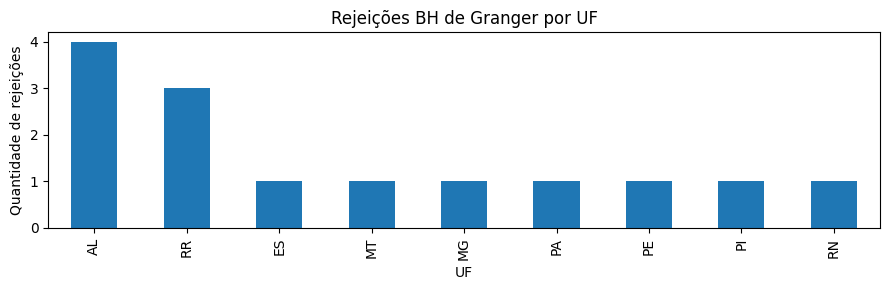

In [5]:
counts=sig.groupby('uf').size().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,3))
counts.plot.bar(ax=ax)
ax.set_title('Rejeições BH de Granger por UF')
ax.set_ylabel('Quantidade de rejeições');ax.set_xlabel('UF');plt.tight_layout();plt.show()

## 6. Interpretação e alertas

A evidência de precedência preditiva é localizada. Os dois casos de Alagamentos em RR rejeitam o Ljung–Box, portanto seus p-valores clássicos exigem ressalva. A seleção por BIC não entra formalmente na distribuição do teste F. Resultados de tipologias com séries idênticas não representam evidências independentes.